In [8]:
import import_ipynb
import data_analysis
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [9]:
reg_features = ['Income_Category', 'Card_Category_Blue', 'Total_Trans_Amt',
                 'Card_Category_Silver', 'Total_Trans_Ct', 'Card_Category_Gold',
                 'Dependent_count']

Xr_train = data_analysis.Xr_train[reg_features]
Xr_test = data_analysis.Xr_test[reg_features]
yr_train = data_analysis.yr_train
yr_test = data_analysis.yr_test

continuous_cols = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Dependent_count']
scaler = StandardScaler()
Xr_train_scaled = Xr_train.copy()
Xr_test_scaled = Xr_test.copy()
Xr_train_scaled[continuous_cols] = scaler.fit_transform(Xr_train[continuous_cols])
Xr_test_scaled[continuous_cols] = scaler.transform(Xr_test[continuous_cols])

# index ตาม reg_features: 0=Income_Category, 1=Card_Category_Blue, 2=Total_Trans_Amt,
# 3=Card_Category_Silver, 4=Total_Trans_Ct, 5=Card_Category_Gold, 6=Dependent_count
spline_features = [0, 1, 2, 3, 4, 5, 6]   # ให้ card dummy เข้า spline ได้ด้วย
fixed_linear_features = []

In [10]:
class MARS:
    def __init__(self, max_terms=25, n_knots=20, gcv_penalty=3, max_degree=1):
        self.max_terms = max_terms
        self.n_knots = n_knots
        self.gcv_penalty = gcv_penalty
        self.max_degree = max_degree
        self.basis_functions = []
        self.fixed_linear_features = []
        self.coef_ = None
        self.forward_history = []
        self.forward_snapshots = []
        self.prune_history = []

    @staticmethod
    def _hinge(x, knot, sign):
        if sign == 1:
            return np.maximum(0, x - knot)
        return np.maximum(0, knot - x)

    def _term_column(self, X, term):
        col = np.ones(X.shape[0])
        for (f_idx, knot, sign) in term:
            col = col * self._hinge(X[:, f_idx], knot, sign)
        return col

    def _build_design_matrix(self, X, basis_functions):
        n = X.shape[0]
        B = np.ones((n, 1))
        for f_idx in self.fixed_linear_features:
            B = np.hstack([B, X[:, f_idx].reshape(-1, 1)])
        for term in basis_functions:
            col = self._term_column(X, term).reshape(-1, 1)
            B = np.hstack([B, col])
        return B

    def _fit_linear(self, B, y):
        coef, *_ = np.linalg.lstsq(B, y, rcond=None)
        return coef

    def _rss(self, B, y, coef):
        return np.sum((y - B @ coef) ** 2)

    def _gcv(self, B, y, coef):
        n = len(y)
        rss = self._rss(B, y, coef)
        terms = B.shape[1]
        effective_params = terms + self.gcv_penalty * (terms - 1) / 2
        denom = (1 - effective_params / n) ** 2
        return (rss / n) / denom if denom > 0 else np.inf

    def fit(self, X, y, spline_features, fixed_linear_features):
        X = np.asarray(X)
        y = np.asarray(y).ravel()
        self.fixed_linear_features = fixed_linear_features
        self.basis_functions = []

        B0 = self._build_design_matrix(X, [])
        self.forward_history = [(0, self._rss(B0, y, self._fit_linear(B0, y)))]
        self.forward_snapshots = [[]]

        improved = True
        while improved and len(self.basis_functions) < self.max_terms:
            B_current = self._build_design_matrix(X, self.basis_functions)
            current_rss = self._rss(B_current, y, self._fit_linear(B_current, y))

            best_rss, best_candidate = None, None
            parents = [()] + [t for t in self.basis_functions if len(t) < self.max_degree]
            for parent in parents:
                used_features = {f for (f, k, s) in parent}
                for f_idx in spline_features:
                    if f_idx in used_features:
                        continue
                    knots = np.percentile(X[:, f_idx], np.linspace(2, 98, self.n_knots))
                    for knot in knots:
                        term_pos = parent + ((f_idx, knot, 1),)
                        term_neg = parent + ((f_idx, knot, -1),)
                        trial = self.basis_functions + [term_pos, term_neg]
                        B_trial = self._build_design_matrix(X, trial)
                        coef_trial = self._fit_linear(B_trial, y)
                        rss_trial = self._rss(B_trial, y, coef_trial)
                        if best_rss is None or rss_trial < best_rss:
                            best_rss, best_candidate = rss_trial, (term_pos, term_neg)

            if best_rss is not None and best_rss < current_rss - 1e-6:
                self.basis_functions += list(best_candidate)
                self.forward_history.append((len(self.basis_functions), best_rss))
                self.forward_snapshots.append(list(self.basis_functions))
            else:
                improved = False

        self._prune(X, y)
        B_final = self._build_design_matrix(X, self.basis_functions)
        self.coef_ = self._fit_linear(B_final, y)
        return self

    def _prune(self, X, y):
        current = list(self.basis_functions)
        B = self._build_design_matrix(X, current)
        best_gcv = self._gcv(B, y, self._fit_linear(B, y))
        best_functions = list(current)
        self.prune_history = [(len(current), best_gcv)]

        while len(current) > 0:
            gcvs = []
            for i in range(len(current)):
                trial = current[:i] + current[i + 1:]
                B_trial = self._build_design_matrix(X, trial)
                gcvs.append(self._gcv(B_trial, y, self._fit_linear(B_trial, y)))

            min_idx = int(np.argmin(gcvs))
            current = current[:min_idx] + current[min_idx + 1:]
            self.prune_history.append((len(current), gcvs[min_idx]))

            if gcvs[min_idx] < best_gcv:
                best_gcv = gcvs[min_idx]
                best_functions = list(current)

        self.basis_functions = best_functions

    def predict(self, X):
        X = np.asarray(X)
        B = self._build_design_matrix(X, self.basis_functions)
        return B @ self.coef_

    def describe_terms(self, feature_names=None):
        def name(i):
            return feature_names[i] if feature_names else f"x{i}"
        lines = []
        for term in self.basis_functions:
            parts = []
            for (f_idx, knot, sign) in term:
                if sign == 1:
                    parts.append(f"max(0, {name(f_idx)} - {knot:.3g})")
                else:
                    parts.append(f"max(0, {knot:.3g} - {name(f_idx)})")
            lines.append(" * ".join(parts))
        return lines

In [11]:
mars_model = MARS(max_terms=25, n_knots=20, gcv_penalty=3, max_degree=2)
mars_model.fit(Xr_train_scaled.values, yr_train, spline_features, fixed_linear_features)

y_pred_mars = mars_model.predict(Xr_test_scaled.values)

print("จำนวน basis function หลัง pruning:", len(mars_model.basis_functions))
print("R² =", r2_score(yr_test, y_pred_mars))
print("MSE =", mean_squared_error(yr_test, y_pred_mars))
print("MAE =", mean_absolute_error(yr_test, y_pred_mars))

print("\nbasis functions:")
for line in mars_model.describe_terms(feature_names=reg_features):
    print(" -", line)

จำนวน basis function หลัง pruning: 13
R² = 0.5629196264591529
MSE = 36180078.41765115
MAE = 4052.1674811778653

basis functions:
 - max(0, Card_Category_Blue - 0) * max(0, Total_Trans_Amt - 0.0747)
 - max(0, Card_Category_Blue - 0) * max(0, 0.964 - Total_Trans_Amt)
 - max(0, Card_Category_Blue - 0) * max(0, Total_Trans_Amt - -0.186)
 - max(0, Card_Category_Blue - 0) * max(0, Income_Category - 2)
 - max(0, Card_Category_Blue - 0) * max(0, 2 - Income_Category)
 - max(0, Income_Category - 1) * max(0, Dependent_count - 0.516)
 - max(0, Income_Category - 2)
 - max(0, 2 - Income_Category)
 - max(0, Card_Category_Blue - 0) * max(0, Total_Trans_Amt - -0.554)
 - max(0, Card_Category_Blue - 0) * max(0, -0.554 - Total_Trans_Amt)
 - max(0, Card_Category_Blue - 0) * max(0, Total_Trans_Amt - -0.985)
 - max(0, Card_Category_Silver - 0)
 - max(0, Card_Category_Blue - 0) * max(0, 0.0464 - Total_Trans_Ct)


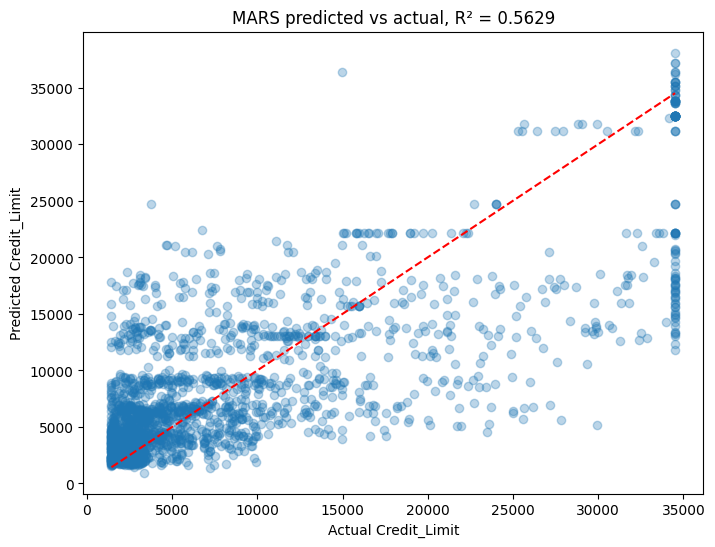

In [12]:
plt.figure(figsize=(8,6))
plt.scatter(yr_test, y_pred_mars, alpha=0.3)
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Actual Credit_Limit')
plt.ylabel('Predicted Credit_Limit')
plt.title(f'MARS predicted vs actual, R² = {r2_score(yr_test, y_pred_mars):.4f}')
plt.show()

In [15]:
import time

def mars_cv_r2(X, y, spline_features, fixed_linear_features, k=5, seed=42, **mars_kwargs):
    X = np.asarray(X)
    y = np.asarray(y).ravel()
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    folds = np.array_split(idx, k)

    scores = []
    for i in range(k):
        t0 = time.time()
        val_idx = folds[i]
        tr_idx = np.concatenate([folds[j] for j in range(k) if j != i])

        m = MARS(**mars_kwargs)
        m.fit(X[tr_idx], y[tr_idx], spline_features, fixed_linear_features)
        r2 = r2_score(y[val_idx], m.predict(X[val_idx]))
        scores.append(r2)
        print(f"fold {i+1}/{k}: R² = {r2:.4f}, terms = {len(m.basis_functions)}, {time.time()-t0:.0f}s")
    return np.array(scores)

cv_scores = mars_cv_r2(
    Xr_train_scaled.values, yr_train,
    spline_features, fixed_linear_features,
    k=5, max_terms=25, n_knots=20, gcv_penalty=3, max_degree=2
)
print(f"\nCV R² mean = {cv_scores.mean():.4f}, std = {cv_scores.std():.4f}")
print(f"test R² = {r2_score(yr_test, y_pred_mars):.4f}")

fold 1/5: R² = 0.5547, terms = 14, 72s
fold 2/5: R² = 0.6090, terms = 14, 40s
fold 3/5: R² = 0.5463, terms = 16, 37s
fold 4/5: R² = 0.6036, terms = 14, 37s
fold 5/5: R² = 0.5455, terms = 14, 42s

CV R² mean = 0.5718, std = 0.0284
test R² = 0.5629


In [13]:
import os, pickle
os.makedirs("models", exist_ok=True)

def save_model(model, path):
    """บันทึกโมเดลที่ fit แล้ว ทั้ง hyperparameter และ parameter ที่เรียนได้ ลงไฟล์"""
    with open(path, "wb") as f:
        pickle.dump(model, f)

def load_model(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def check_save_load(model, path, X_test, name):
    """save -> load -> predict บนข้อมูล test แล้วเทียบกับโมเดลต้นฉบับ  max_abs_diff ควรเป็น 0"""
    save_model(model, path)
    reloaded = load_model(path)
    diff = float(np.max(np.abs(np.asarray(model.predict(X_test)) - np.asarray(reloaded.predict(X_test)))))
    return {"model": name, "file": path, "size_kb": round(os.path.getsize(path) / 1024, 1), "max_abs_diff": diff}

In [14]:
# บันทึกโมเดล แล้วโหลดกลับมาทดสอบกับ test set
check_save_load(mars_model, "models/mars.pkl", Xr_test_scaled.values, "MARS")

{'model': 'MARS',
 'file': 'models/mars.pkl',
 'size_kb': 2.3,
 'max_abs_diff': 0.0}